In [1]:
from momentum import momentum_strategy
from backtester import run_backtest
import metrics
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
prices = pd.read_csv("data/prices.csv", index_col=0, parse_dates=True)
returns = prices.pct_change()

### Parameter sweep

In [11]:
lookbacks = [3,6,9,12]
top_ns = [2,3,5]
results = {}
starts = []

for lookback in lookbacks:
    for top_n in top_ns:
        weights = momentum_strategy(prices, lookback=lookback, top_n=top_n)
        results[(lookback, top_n)] = run_backtest(weights, returns, cost=0.001)
        starts.append((weights.shift(1).sum(axis=1) > 0).idxmax())

common_start = max(starts)

sharpe_ratios = pd.DataFrame(index=lookbacks, columns=top_ns, dtype=float)
for (lookback, top_n), strat_returns in results.items():
    sharpe_ratios.loc[lookback, top_n] = metrics.sharpe_ratio(strat_returns.loc[common_start:])

spy_sharpe = metrics.sharpe_ratio(returns["SPY"].loc[common_start:])
print(common_start, spy_sharpe)
sharpe_ratios

2011-02-01 00:00:00 0.8642731683163246


,2,3,5
3,0.654436,0.661027,0.842990
6,0.486739,0.679643,0.788160
9,0.398178,0.629173,0.872396
12,0.601190,0.733577,0.760301


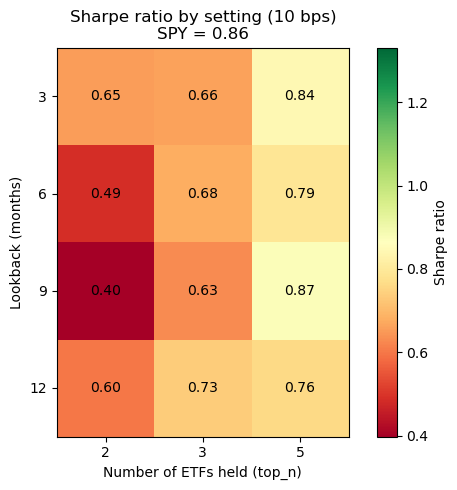

In [13]:
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(6, 5))

d = (sharpe_ratios - spy_sharpe).abs().max().max()
norm = TwoSlopeNorm(vcenter=spy_sharpe, vmin=spy_sharpe - d, vmax=spy_sharpe + d)
im = ax.imshow(sharpe_ratios.values, cmap="RdYlGn", norm=norm)

ax.set_xticks(range(len(top_ns)))
ax.set_xticklabels(top_ns)
ax.set_yticks(range(len(lookbacks)))
ax.set_yticklabels(lookbacks)
ax.set_xlabel("Number of ETFs held (top_n)")
ax.set_ylabel("Lookback (months)")
ax.set_title(f"Sharpe ratio by setting (10 bps)\nSPY = {spy_sharpe:.2f}")

for i in range(len(lookbacks)):
    for j in range(len(top_ns)):
        ax.text(j, i, f"{sharpe_ratios.iloc[i, j]:.2f}", ha="center", va="center")

fig.colorbar(im, ax=ax, label="Sharpe ratio")
fig.tight_layout()
fig.savefig("figures/sharpe_sweep_heatmap.png")
plt.show()

Sharpe ratios range from 0.40 to 0.87 across the 12 settings (a spread of 0.47),
so results are sensitive to the choice of lookback and number of holdings. The
original 12 month, top3 choice (0.73) is typical, sitting near the middle of
the range (median being 0.67). Only one version beats SPY (0.86): 9 months, top 5, at 0.87, and only
by a very small margin. Reporting that best version alone would be misleading,
because picking the best of 12 attempts after seeing the results biases its
performance upwards: some of its advantage is likely luck rather than a real edge.


In every row, the Sharpe ratio increases as top_n rises from 2 to 5, making the number
of holdings a more consistent driver of performance than the lookback length. Holding
more ETFs diversifies the portfolio: it reduces the impact of any single bad pick and
makes the strategy behave more like the overall ETF universe, which is itself closely
tied to the US market.

### Out of sample test

In [22]:
sharpe_ratios_insample = pd.DataFrame(index=lookbacks, columns=top_ns, dtype=float)
sharpe_ratios_outsample = pd.DataFrame(index=lookbacks, columns=top_ns, dtype=float)
spy_sharpe_insample = metrics.sharpe_ratio(returns["SPY"].loc[common_start:"2018"])
spy_sharpe_outsample = metrics.sharpe_ratio(returns["SPY"].loc["2019":])

for (lookback, top_n), strat_returns in results.items():
    sharpe_ratios_insample.loc[lookback, top_n] = metrics.sharpe_ratio(strat_returns.loc[common_start:"2018"])
    sharpe_ratios_outsample.loc[lookback, top_n] = metrics.sharpe_ratio(strat_returns.loc["2019":])



In [18]:
sharpe_ratios_insample

,2,3,5
3,0.543653,0.604993,0.810165
6,0.442834,0.630907,0.680411
9,0.291734,0.511666,0.668963
12,0.423539,0.326444,0.472899


In [16]:
sharpe_ratios_outsample

,2,3,5
3,0.750848,0.715197,0.882132
6,0.528411,0.727332,0.885535
9,0.485531,0.733227,1.055324
12,0.752614,1.092776,1.022979


In [23]:
spy_sharpe_outsample
spy_sharpe_insample

np.float64(0.7911473085413303)

In [24]:
sharpe_ratios_insample.stack().corr(sharpe_ratios_outsample.stack(), method="spearman")

np.float64(0.2377622377622378)

The best in-sample setting (3 months, top 5, Sharpe 0.81) did not stay the best: out of
sample it scored 0.88, ranking 5th of 12 and below SPY's 0.94. All 12 settings had higher
Sharpe ratios after 2019, but SPY did too (in-sample 0.79, out-of-sample 0.94), so much of
this reflects a stronger market period rather than the strategy improving. Rankings were
unstable: the original 12/3 was the second worst in-sample (0.33) but the best out of
sample (1.09), and the rank correlation between in-sample and out-of-sample Sharpe ratios
was 0.24. Choosing settings based on past backtest performance would not have reliably
picked a good setting here, which suggests most of the differences between settings are
noise rather than genuine differences in quality.

The top_n pattern largely holds in both halves. Top 5 beats top 2 for every lookback in
both periods, and averaged across lookbacks the Sharpe ratio rises with top_n in each
half. The increase is
not perfectly smooth, but
unlike the best individual setting, the benefit of holding more ETFs is consistent across
periods, making it the most robust finding of the sweep.

### Newey-West standard errors

In [27]:
strategy_monthly = (1 + results[(12,3)][common_start:]).resample("ME").prod() - 1
spy_monthly = (1 + returns["SPY"][common_start:]).resample('ME').prod() -1


import statsmodels.api as sm

X = sm.add_constant(spy_monthly)  
model_nw = sm.OLS(strategy_monthly, X).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(model_nw.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.476
Model:                            OLS   Adj. R-squared:                  0.473
Method:                 Least Squares   F-statistic:                     89.19
Date:                Thu, 15 Oct 2026   Prob (F-statistic):           1.48e-17
Time:                        18:15:56   Log-Likelihood:                 417.80
No. Observations:                 189   AIC:                            -831.6
Df Residuals:                     187   BIC:                            -825.1
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0015      0.002      0.766      0.4

To check how reliable the Phase 5 regression is, I reran it with Newey–West standard
errors, which allow for some months being much more volatile than others. The estimates
of alpha and beta stay the same; only the uncertainty around them changes.

Beta becomes slightly less certain: its 95% confidence interval widens from 0.53–0.72 to
0.50–0.76. But it is still clearly above 0 and below 1, so the strategy definitely carries
some market exposure, and less than SPY.

Alpha is still not statistically significant (p = 0.44), so there is still no reliable
evidence that the strategy earns returns beyond its market exposure.

The research conclusions therefore hold under this more careful method.

### Sub-Peroid analysis

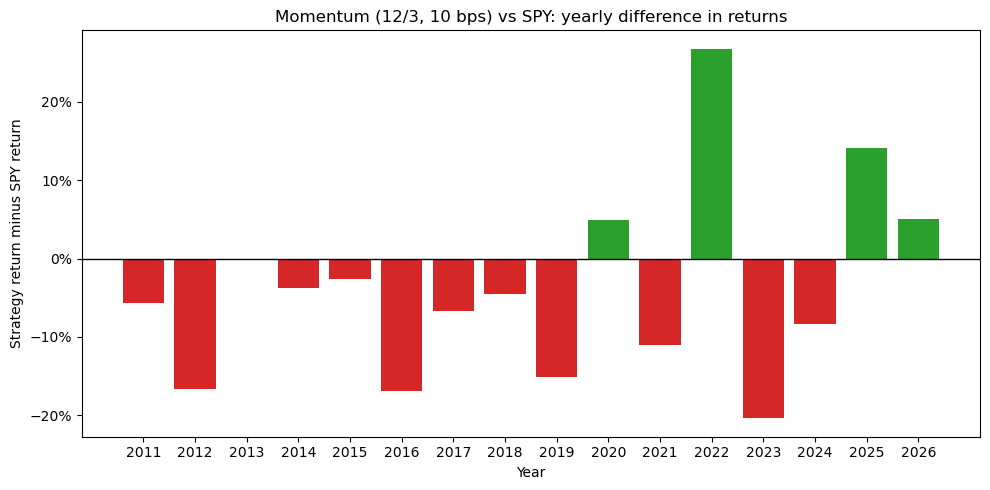

In [34]:
strategy_yearly = (1 + results[(12,3)][common_start:]).resample("YE").prod() - 1
spy_yearly = (1 + returns["SPY"][common_start:]).resample('YE').prod() -1

difference = strategy_yearly-spy_yearly


# Create bar chart
from matplotlib.ticker import PercentFormatter

years = difference.index.year
colours = ["tab:green" if d > 0 else "tab:red" for d in difference]

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(years, difference.values, color=colours)
ax.axhline(0, color="black", linewidth=1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xticks(years)
ax.set_xlabel("Year")
ax.set_ylabel("Strategy return minus SPY return")
ax.set_title("Momentum (12/3, 10 bps) vs SPY: yearly difference in returns")
fig.tight_layout()
fig.savefig("figures/yearly_difference_vs_spy.png")
plt.show()


**note: 2011 and 2026 are not full years**

The strategy beat SPY in only 4 of 16 calendar years (2020, 2022, 2025 and the partial
2026), and lagged in the other 12. The years it beat SPY were mostly difficult markets,
with 2022 standing out (+27% relative to SPY). Its worst years relative to SPY (2012,
2016, 2019 and 2023, each around −15% to −20%) were strong market years, often rebounds,
when the strategy was slow to move out of last year's winners.

This partly supports hypothesis 3: the strategy's gains are concentrated in a few key
periods, especially 2022. But its underperformance is not: it lagged SPY in most years,
so the overall result is not driven by just a few bad periods.

### Break-even cost

In [44]:
settings = [(12,3), (9,5), (3,5)] #choosing settings (12,3): original, (9,5): best full period, (3,5): best in period
labels = [f"{lookback}/{top_n}" for lookback,top_n in settings]

sharpe_ratios_costs = pd.DataFrame(index=range(0,51,5), columns=labels, dtype=float)

for (lookback, top_n) in settings:
        weights = momentum_strategy(prices, lookback=lookback, top_n=top_n)
        for cost in range(0,51,5):
            sharpe_ratios_costs.loc[cost, f"{lookback}/{top_n}"] = metrics.sharpe_ratio(run_backtest(weights, returns, cost*0.0001).loc[common_start:])
print(sharpe_ratios_costs)


        12/3       9/5       3/5
0   0.775509  0.906145  0.905357
5   0.754570  0.889289  0.874222
10  0.733577  0.872396  0.842990
15  0.712535  0.855469  0.811672
20  0.691446  0.838510  0.780276
25  0.670316  0.821521  0.748811
30  0.649147  0.804504  0.717288
35  0.627943  0.787460  0.685717
40  0.606709  0.770393  0.654106
45  0.585448  0.753303  0.622465
50  0.564164  0.736193  0.590804


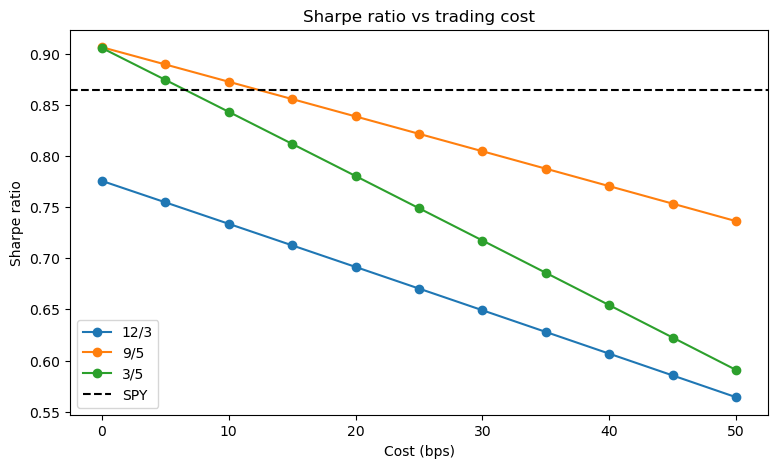

In [46]:
fig, ax = plt.subplots(figsize=(9, 5))
sharpe_ratios_costs.plot(ax=ax, marker="o")
ax.axhline(spy_sharpe, color="black", linestyle="--", label="SPY")
ax.set_xlabel("Cost (bps)")
ax.set_ylabel("Sharpe ratio")
ax.set_title("Sharpe ratio vs trading cost")
ax.legend()
fig.savefig("figures/sharpe_vs_cost.png")
plt.show()

At zero cost, both 9/5 and 3/5 beat SPY's Sharpe ratio (0.91 vs 0.86), but their
advantage disappears quickly: at about 6–7 bps for 3/5 and about 12 bps for 9/5. The
original 12/3 never beats SPY, and the gap widens as costs rise.

3/5 is the most cost-sensitive setting: from 0 to 50 bps its Sharpe ratio falls by about
0.32, compared with 0.17 for 9/5 and 0.21 for 12/3. A 3 month lookback changes its
rankings more often than a 9 or 12 month one, so it trades more, and pays more in costs.

Bid–ask spreads for liquid ETFs like SPY are typically well under 1 bp, and a few bps
for sector ETFs and EEM, so 10 bps is a conservative assumption for a small investor.
At realistic costs, 9/5 would likely stay slightly ahead of SPY, but its edge is small
and, as the out-of-sample test showed, the best setting is not stable over time.

### Next day open execution